# Sesión 07. Modelos de difusión: del ruido a la imagen

El video que motiva esta sesión es una escalera de frases encadenadas:

1. Si le sumas ruido a un número, obtienes un número ligeramente distinto.
2. Si ese número describe un píxel, obtienes una imagen ruidosa.
3. Si sigues sumando ruido a la imagen, obtienes ruido puro.
4. Si entrenas una red neuronal para revertir esto, obtienes un modelo que quita ruido.
5. Si además le dices a esa red qué quieres ver, obtienes eliminación de ruido condicional.
6. Si la entrenas con imágenes en todos los niveles de ruido, obtienes difusión.
7. Si la entrenas con millones de imágenes y sus descripciones, obtienes un generador como los comerciales.
8. Y si rebobinas todo, vuelves al ruido.

En este cuaderno subimos esa escalera con código y ecuaciones:

1. Un número más ruido: la gaussiana y la reparametrización.
2. El proceso directo $q(\mathbf{x}_t\mid\mathbf{x}_{t-1})$ y los horarios de ruido lineal y coseno.
3. La forma cerrada $\mathbf{x}_t=\sqrt{\bar\alpha_t}\,\mathbf{x}_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon$, comprobada numéricamente.
4. Una red que predice el ruido y la pérdida simplificada $\lVert\boldsymbol\epsilon-\boldsymbol\epsilon_\theta(\mathbf{x}_t,t)\rVert^2$.
5. El muestreo inverso paso a paso sobre una nube de puntos 2D con forma de montañas al atardecer.
6. El campo de *score* que empuja a las partículas hacia los datos.
7. Imágenes: paisajes de pixel art con "prompt" y dígitos de MNIST, con guía sin clasificador.

El cuaderno se genera con `scripts/build_difusion_notebook.py`. Las secciones 7 y 8 cargan los modelos que entrena `scripts/train_ddpm.py`.

In [1]:
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "scripts" / "train_ddpm.py").exists():
            return parent
    for c in ["/workspace/friendly-fiesta", "/workspace"]:
        if (Path(c) / "scripts" / "train_ddpm.py").exists():
            return Path(c)
    return p


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT / "scripts"))
import train_ddpm as td  # noqa: E402  (formas 2D, MLP, U-Net y horarios)

RUN = ROOT / "data" / "difusion_run"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NARANJA, PIZARRA = "#FF5900", "#262C34"
print("dispositivo:", DEVICE, "| raíz:", ROOT)

dispositivo: cuda | raíz: /workspace/friendly-fiesta


## 1. Un número más ruido

El video empieza con un solo píxel que vale $0.67$ y un número aleatorio $\epsilon$. La suma es otro número parecido. Si $\epsilon\sim\mathcal N(0,1)$ y lo escalamos por $\sigma$, la suma $x+\sigma\epsilon$ es una gaussiana con media $x$ y varianza $\sigma^2$:

$$x+\sigma\epsilon\sim\mathcal N(x,\sigma^2).$$

Esto es la **reparametrización**: para muestrear de $\mathcal N(\mu,\sigma^2)$ basta muestrear ruido estándar y aplicar $\mu+\sigma\epsilon$. Toda la difusión descansa sobre esta línea.

sigma=0.05: media=0.670  desviación=0.050
sigma=0.20: media=0.671  desviación=0.200
sigma=0.60: media=0.671  desviación=0.598


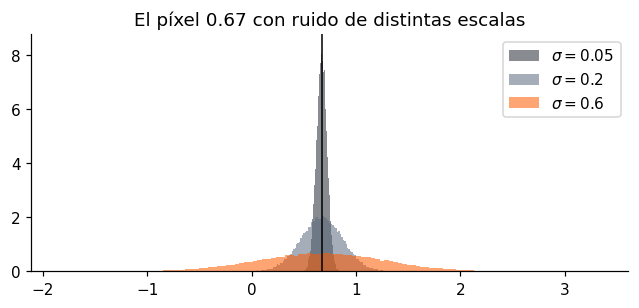

In [2]:
rng = np.random.default_rng(SEED)
x = 0.67
for sigma in [0.05, 0.2, 0.6]:
    muestras = x + sigma * rng.standard_normal(100_000)
    print(f"sigma={sigma:.2f}: media={muestras.mean():.3f}  desviación={muestras.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
for sigma, c in zip([0.05, 0.2, 0.6], [PIZARRA, "#5B6B7F", NARANJA]):
    ax.hist(x + sigma * rng.standard_normal(50_000), bins=120, density=True, alpha=0.55, color=c, label=f"$\\sigma={sigma}$")
ax.axvline(x, color="k", lw=1)
ax.set_title("El píxel 0.67 con ruido de distintas escalas")
ax.legend()
plt.show()

## 2. El proceso directo y los horarios de ruido

Cada paso del proceso directo encoge un poco la señal y le suma un poco de ruido:

$$q(\mathbf{x}_t\mid\mathbf{x}_{t-1})=\mathcal N\!\left(\sqrt{1-\beta_t}\,\mathbf{x}_{t-1},\ \beta_t\mathbf I\right),\qquad t=1,\dots,T.$$

El factor $\sqrt{1-\beta_t}$ evita que la varianza explote: si $\mathbf x_{t-1}$ tiene varianza 1, $\mathbf x_t$ también. Definimos $\alpha_t=1-\beta_t$ y $\bar\alpha_t=\prod_{s=1}^t\alpha_s$, la fracción de señal que sobrevive hasta el paso $t$.

Dos horarios clásicos:

* **Lineal** (Ho et al., 2020): $\beta_t$ crece linealmente de $10^{-4}$ a $0.02$ con $T=1000$.
* **Coseno** (Nichol y Dhariwal, 2021): $\bar\alpha_t=f(t)/f(0)$ con $f(t)=\cos^2\!\left(\frac{t/T+s}{1+s}\cdot\frac{\pi}{2}\right)$, $s=0.008$.

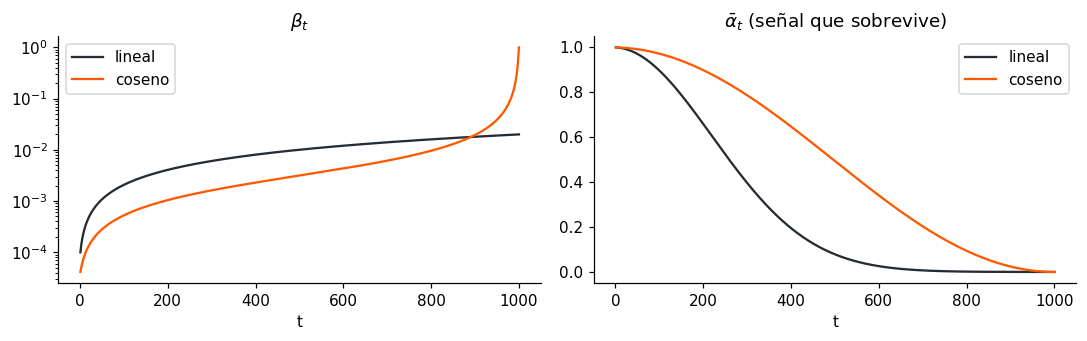

lineal : alpha_bar_T = 4.04e-05;  la señal cae a la mitad en t = 259
coseno : alpha_bar_T = 2.43e-09;  la señal cae a la mitad en t = 496


In [3]:
T = 1000
b_lin, b_cos = td.horario_lineal(T), td.horario_coseno(T)
ab_lin, ab_cos = np.cumprod(1 - b_lin), np.cumprod(1 - b_cos)
t = np.arange(1, T + 1)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(t, b_lin, color=PIZARRA, label="lineal")
axs[0].plot(t, b_cos, color=NARANJA, label="coseno")
axs[0].set_yscale("log"); axs[0].set_title(r"$\beta_t$"); axs[0].legend()
axs[1].plot(t, ab_lin, color=PIZARRA, label="lineal")
axs[1].plot(t, ab_cos, color=NARANJA, label="coseno")
axs[1].set_title(r"$\bar\alpha_t$ (señal que sobrevive)"); axs[1].legend()
for a in axs: a.set_xlabel("t")
plt.tight_layout(); plt.show()

for nombre, ab in [("lineal", ab_lin), ("coseno", ab_cos)]:
    mitad = int(np.argmin(np.abs(ab - 0.5))) + 1
    print(f"{nombre:7s}: alpha_bar_T = {ab[-1]:.2e};  la señal cae a la mitad en t = {mitad}")

El horario lineal destruye la información muy pronto: a la mitad del trayecto casi no queda señal y los últimos cientos de pasos se gastan en ruido casi puro. El coseno reparte la destrucción de manera más pareja, cosa que se nota sobre todo en imágenes pequeñas.

## 3. La forma cerrada, comprobada con números

Componiendo los pasos (la suma de gaussianas independientes es gaussiana y las varianzas se suman) se llega a

$$q(\mathbf{x}_t\mid\mathbf{x}_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}\,\mathbf{x}_0,\ (1-\bar\alpha_t)\mathbf I\right)
\quad\Longleftrightarrow\quad
\mathbf{x}_t=\sqrt{\bar\alpha_t}\,\mathbf{x}_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon .$$

El apunte trae la demostración por inducción. Aquí lo comprobamos: aplicamos 300 pasos uno por uno sobre la nube de montañas y comparamos con un solo salto en forma cerrada.

alpha_bar_300 = 0.3964
paso a paso : media [ 0.016 -0.145]  var [1.068 0.906]
forma cerrada: media [ 0.021 -0.14 ]  var [1.057 0.899]


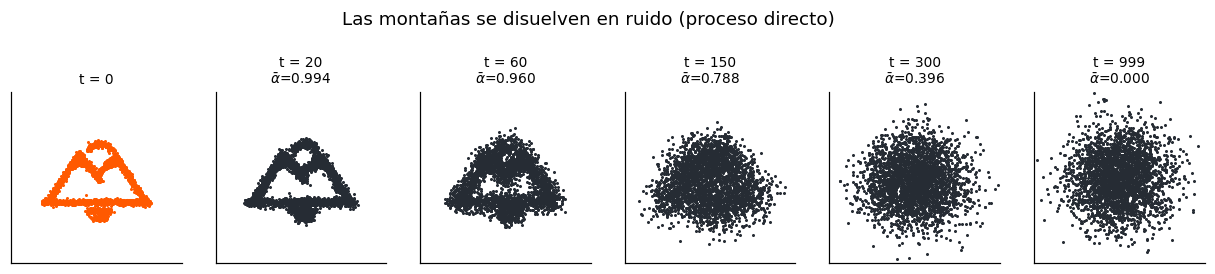

In [4]:
x0 = td.muestrear_trazos(td.forma_montanas(), 20_000, np.random.default_rng(SEED))
t_obj = 300
x = x0.copy()
for s in range(t_obj):
    x = math.sqrt(1 - b_lin[s]) * x + math.sqrt(b_lin[s]) * rng.standard_normal(x.shape)
salto = math.sqrt(ab_lin[t_obj - 1]) * x0 + math.sqrt(1 - ab_lin[t_obj - 1]) * rng.standard_normal(x0.shape)

print(f"alpha_bar_{t_obj} = {ab_lin[t_obj - 1]:.4f}")
print("paso a paso : media", x.mean(0).round(3), " var", x.var(0).round(3))
print("forma cerrada: media", salto.mean(0).round(3), " var", salto.var(0).round(3))

fig, axs = plt.subplots(1, 6, figsize=(14, 2.6))
for a, tt in zip(axs, [0, 20, 60, 150, 300, 999]):
    xt = x0 if tt == 0 else math.sqrt(ab_lin[tt - 1]) * x0 + math.sqrt(1 - ab_lin[tt - 1]) * rng.standard_normal(x0.shape)
    a.scatter(xt[:3000, 0], xt[:3000, 1], s=1, color=NARANJA if tt == 0 else PIZARRA)
    a.set_xlim(-3.5, 3.5); a.set_ylim(-3.5, 3.5); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"t = {tt}" + ("" if tt == 0 else f"\n$\\bar\\alpha$={ab_lin[tt - 1]:.3f}"), fontsize=9)
plt.suptitle("Las montañas se disuelven en ruido (proceso directo)", y=1.08)
plt.show()

## 4. La red que predice el ruido y la pérdida simplificada

El proceso inverso necesitaría $q(\mathbf x_{t-1}\mid\mathbf x_t)$, que depende de toda la distribución de datos. Lo aproximamos con una red. Ho et al. (2020) mostraron que basta con que la red **adivine el ruido** $\boldsymbol\epsilon$ que se usó para fabricar $\mathbf x_t$:

$$L_{\text{simple}}(\theta)=\mathbb E_{t,\mathbf x_0,\boldsymbol\epsilon}\Big[\big\lVert\boldsymbol\epsilon-\boldsymbol\epsilon_\theta\big(\sqrt{\bar\alpha_t}\,\mathbf x_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon,\ t\big)\big\rVert^2\Big].$$

El algoritmo de entrenamiento cabe en cinco líneas: muestrear $\mathbf x_0$, muestrear $t$ uniforme, muestrear $\boldsymbol\epsilon$, fabricar $\mathbf x_t$ con la forma cerrada y dar un paso de gradiente. La red es un MLP que recibe $(x,y)$ y una codificación sinusoidal de $t$.

8000 pasos en 36.6 s; pérdida final 0.2312


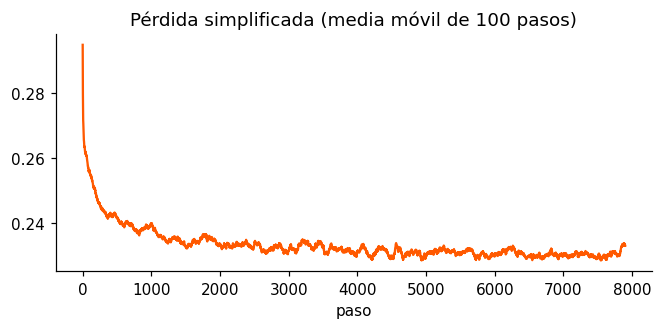

In [5]:
torch.manual_seed(SEED)
dif = td.Difusion(b_lin)
datos = torch.tensor(x0, dtype=torch.float32, device=DEVICE)
red = td.MLP2D().to(DEVICE)
opt = torch.optim.AdamW(red.parameters(), lr=1e-3)
PASOS = 8000
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, PASOS)
perdidas = []
t0 = time.time()
for paso in range(PASOS):
    x0_b = datos[torch.randint(0, len(datos), (2048,), device=DEVICE)]   # 1. datos
    t_b = torch.randint(0, T, (len(x0_b),), device=DEVICE)                # 2. t uniforme (índice 0..T-1)
    eps = torch.randn_like(x0_b)                                          # 3. ruido
    x_t = dif.q_sample(x0_b, t_b, eps)                                    # 4. forma cerrada
    perdida = F.mse_loss(red(x_t, t_b), eps)                              # 5. ||eps - eps_theta||^2
    opt.zero_grad(); perdida.backward(); opt.step(); sched.step()
    perdidas.append(perdida.item())
print(f"{PASOS} pasos en {time.time() - t0:.1f} s; pérdida final {np.mean(perdidas[-300:]):.4f}")

plt.figure(figsize=(7, 2.8))
plt.plot(np.convolve(perdidas, np.ones(100) / 100, mode="valid"), color=NARANJA)
plt.title("Pérdida simplificada (media móvil de 100 pasos)"); plt.xlabel("paso"); plt.show()

La pérdida no baja a cero y no debe hacerlo. Para $t$ pequeño, $\mathbf x_t$ es casi $\mathbf x_0$ y el ruido es una diminuta perturbación de un punto sobre la forma: fácil de adivinar en la dirección perpendicular a la forma y casi imposible a lo largo de ella. Para $t$ grande, $\mathbf x_t$ es casi puro ruido y la mejor apuesta es $\boldsymbol\epsilon_\theta\approx\mathbf x_t$. Veamos la pérdida por nivel de ruido.

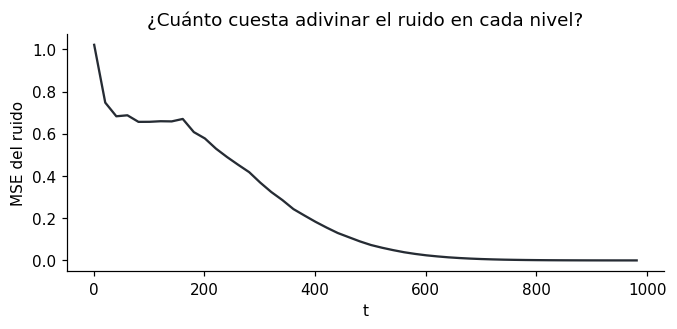

In [6]:
with torch.no_grad():
    xb = datos[:4096]
    ts = np.arange(1, T + 1, 20)
    mse_t = []
    for tt in ts:
        ti = torch.full((len(xb),), tt - 1, device=DEVICE, dtype=torch.long)
        e = torch.randn_like(xb)
        mse_t.append(F.mse_loss(red(dif.q_sample(xb, ti, e), ti), e).item())
plt.figure(figsize=(7, 2.8))
plt.plot(ts, mse_t, color=PIZARRA)
plt.xlabel("t"); plt.ylabel("MSE del ruido"); plt.title("¿Cuánto cuesta adivinar el ruido en cada nivel?")
plt.show()

## 5. Muestreo inverso: rebobinar el video

Con $\boldsymbol\epsilon_\theta$ entrenada, cada paso inverso es una gaussiana cuya media se calcula restando el ruido estimado:

$$\mathbf x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(\mathbf x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\boldsymbol\epsilon_\theta(\mathbf x_t,t)\right)+\sigma_t\mathbf z,\qquad \mathbf z\sim\mathcal N(0,\mathbf I),$$

con $\sigma_t^2=\tilde\beta_t=\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$ y $\mathbf z=0$ en el último paso. Escribimos el bucle explícito (el script usa el mismo en `td.Difusion.muestrear`).

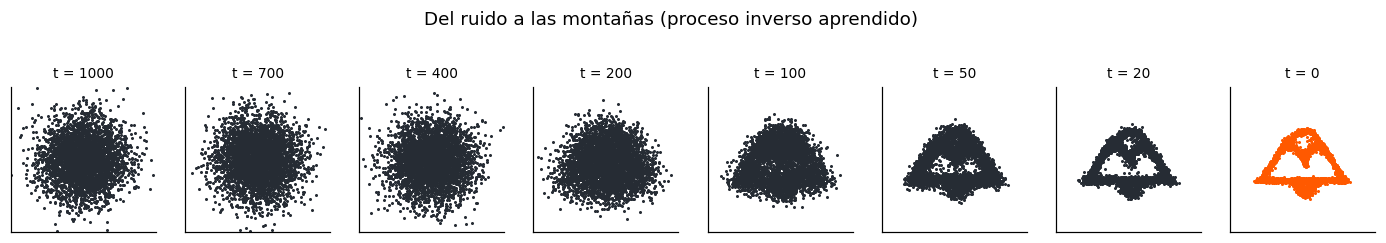

In [7]:
@torch.no_grad()
def muestrear(red, n, guardar=(1000, 700, 400, 200, 100, 50, 20, 0), semilla=SEED):
    g = torch.Generator(device=DEVICE).manual_seed(semilla)
    x = torch.randn((n, 2), device=DEVICE, generator=g)                       # x_T ~ N(0, I)
    fotos = {T: x.cpu().numpy()}
    for t in range(T, 0, -1):
        i = t - 1
        ti = torch.full((n,), i, device=DEVICE, dtype=torch.long)
        eps = red(x, ti)
        media = (x - dif.betas[i] / (1 - dif.ab[i]).sqrt() * eps) / dif.alphas[i].sqrt()
        z = torch.randn((n, 2), device=DEVICE, generator=g) if t > 1 else 0
        x = media + dif.var_post[i].sqrt() * z
        if t - 1 in guardar:
            fotos[t - 1] = x.cpu().numpy()
    return fotos

fotos = muestrear(red, 4000)
fig, axs = plt.subplots(1, len(fotos), figsize=(16, 2.4))
for a, tt in zip(axs, sorted(fotos, reverse=True)):
    p = fotos[tt]
    a.scatter(p[:, 0], p[:, 1], s=1, color=NARANJA if tt == 0 else PIZARRA)
    a.set_xlim(-3.5, 3.5); a.set_ylim(-3.5, 3.5); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"t = {tt}", fontsize=9)
plt.suptitle("Del ruido a las montañas (proceso inverso aprendido)", y=1.06)
plt.show()

## 6. El campo de *score*

La red de ruido es, salvo un factor, el **score** de la distribución ruidosa:

$$\nabla_{\mathbf x_t}\log q(\mathbf x_t)\approx-\frac{\boldsymbol\epsilon_\theta(\mathbf x_t,t)}{\sqrt{1-\bar\alpha_t}}.$$

En cada punto del plano, $-\boldsymbol\epsilon_\theta$ señala hacia donde hay más densidad de datos. Con $t$ grande el campo apunta casi radialmente al origen; con $t$ pequeño se pega a la forma.

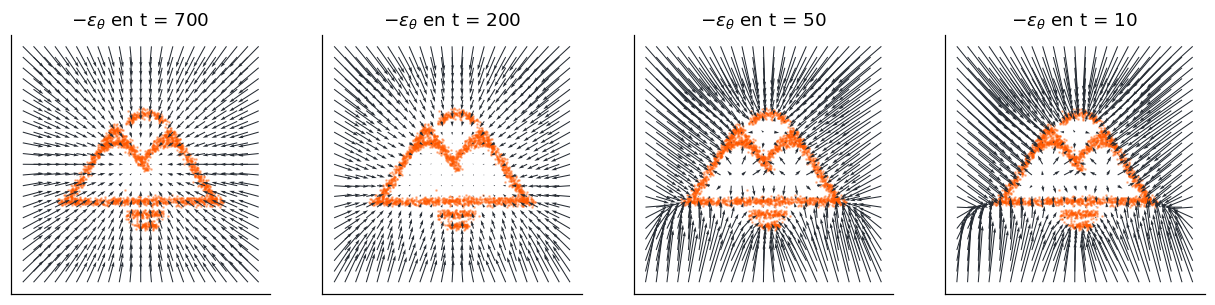

In [8]:
g = np.linspace(-3.2, 3.2, 23)
gx, gy = np.meshgrid(g, g)
rej = torch.tensor(np.stack([gx.ravel(), gy.ravel()], 1), dtype=torch.float32, device=DEVICE)
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
for a, tt in zip(axs, [700, 200, 50, 10]):
    with torch.no_grad():
        e = red(rej, torch.full((len(rej),), tt - 1, device=DEVICE, dtype=torch.long)).cpu().numpy()
    a.scatter(x0[:2500, 0], x0[:2500, 1], s=0.5, color=NARANJA, alpha=0.4)
    a.quiver(gx, gy, -e[:, 0].reshape(gx.shape), -e[:, 1].reshape(gx.shape), color=PIZARRA, scale=40, width=0.004)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_title(f"$-\\epsilon_\\theta$ en t = {tt}")
plt.show()

## 7. Paisajes con "prompt": la escena del video

El video condiciona la red con un texto: "mountains at sunset". Aquí el texto es una de tres etiquetas (montañas al atardecer, ciudad de noche, playa de día) y las imágenes son paisajes de pixel art $24\times24$ generados por procedimiento (`td.paisaje`). La U-Net recibe $(\mathbf x_t,t,c)$; durante el entrenamiento se borra la etiqueta el 15 % de las veces, así la misma red aprende la versión condicional y la incondicional.

Al muestrear se usa **guía sin clasificador** (Ho y Salimans, 2022):

$$\tilde{\boldsymbol\epsilon}=\boldsymbol\epsilon_\theta(\mathbf x_t,t,\varnothing)+w\,\big(\boldsymbol\epsilon_\theta(\mathbf x_t,t,c)-\boldsymbol\epsilon_\theta(\mathbf x_t,t,\varnothing)\big).$$

Con $w=0$ la red ignora el prompt; con $w=1$ es el modelo condicional; con $w>1$ exagera lo que distingue a la clase.

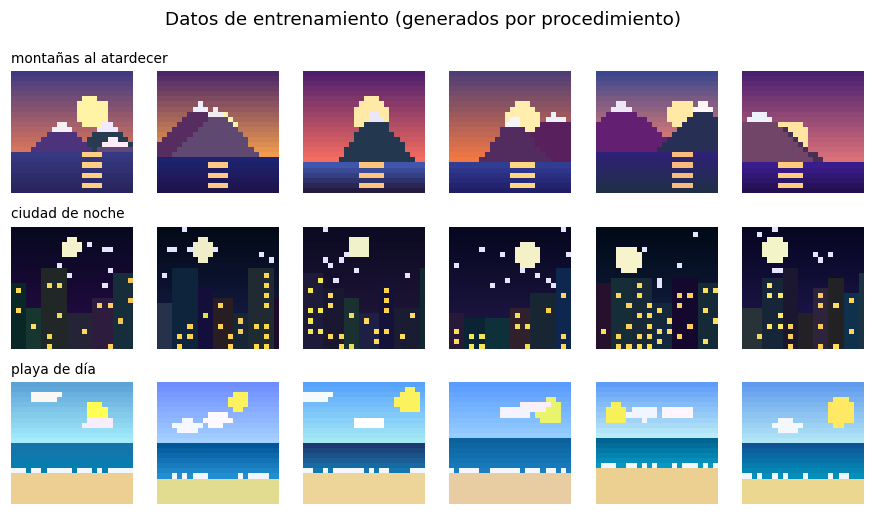

In [9]:
rng_p = np.random.default_rng(SEED)
fig, axs = plt.subplots(3, 6, figsize=(10, 5.2))
for c in range(3):
    for k in range(6):
        axs[c, k].imshow(td.paisaje(c, rng_p), interpolation="nearest")
        axs[c, k].axis("off")
    axs[c, 0].set_title(td.PROMPTS[c], fontsize=9, loc="left")
plt.suptitle("Datos de entrenamiento (generados por procedimiento)")
plt.show()

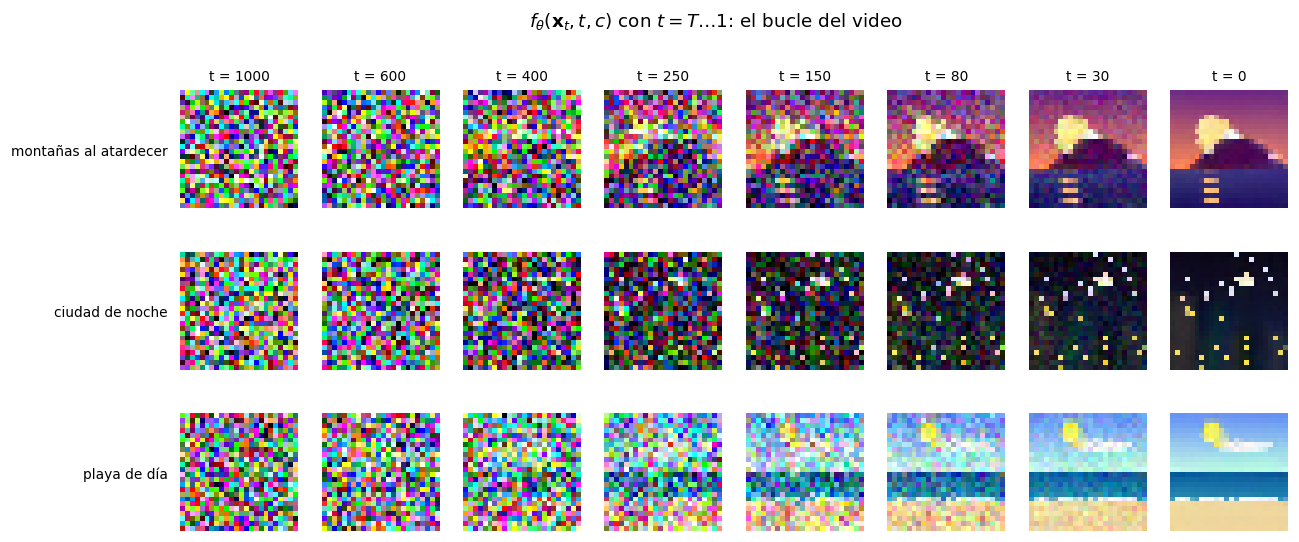

In [10]:
def cargar_unet(nombre, canales, n_clases):
    ruta = RUN / f"unet_{nombre}.pt"
    if not ruta.exists():
        print("Falta", ruta, ": ejecuta antes scripts/train_ddpm.py")
        return None
    m = td.UNet(canales, n_clases).to(DEVICE)
    m.load_state_dict(torch.load(ruta, map_location=DEVICE, weights_only=True)["ema"])
    return m.eval()


def a_img(x):
    x = ((x.clamp(-1, 1) + 1) / 2).cpu().numpy()
    return x.transpose(0, 2, 3, 1) if x.shape[1] == 3 else x[:, 0]


unet_p = cargar_unet("paisajes", 3, 3)
if unet_p is not None:
    reg = [1000, 600, 400, 250, 150, 80, 30, 0]
    y = torch.tensor([0, 1, 2], device=DEVICE)
    g = torch.Generator(device=DEVICE).manual_seed(SEED)
    _, guard = dif.muestrear(unet_p, (3, 3, 24, 24), set(reg), y=y, guia=3.0, recortar=True, gen=g)
    fig, axs = plt.subplots(3, len(reg), figsize=(13, 5.4))
    for j, tt in enumerate(reg):
        im = a_img(guard[tt].to(DEVICE))
        for c in range(3):
            axs[c, j].imshow(im[c], interpolation="nearest"); axs[c, j].axis("off")
            if c == 0: axs[c, j].set_title(f"t = {tt}", fontsize=9)
    for c in range(3):
        axs[c, 0].text(-3, 12, td.PROMPTS[c], ha="right", va="center", fontsize=9)
    plt.suptitle("$f_\\theta(\\mathbf{x}_t, t, c)$ con $t = T\\ldots 1$: el bucle del video", y=1.0)
    plt.show()

## 8. Dígitos de MNIST y el efecto de la guía

La misma U-Net, entrenada sobre MNIST con la etiqueta del dígito como condición. Partimos del **mismo ruido** $\mathbf x_T$ y variamos solo la escala de guía $w$.

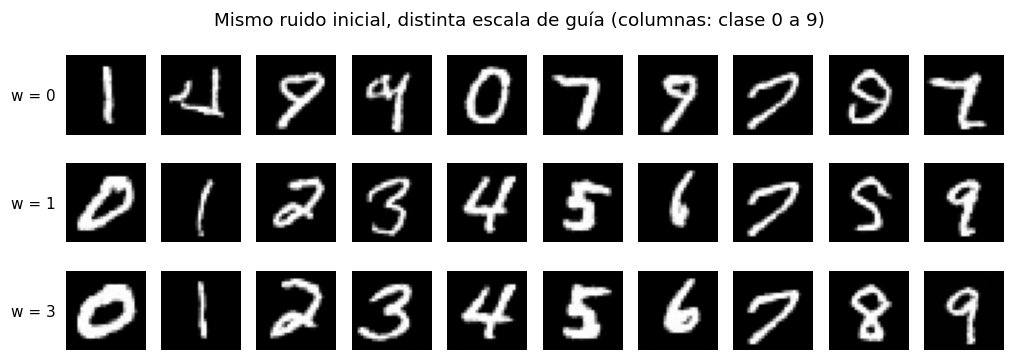

In [11]:
unet_m = cargar_unet("mnist", 1, 10)
if unet_m is not None:
    g0 = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    xT = torch.randn((10, 1, 28, 28), device=DEVICE, generator=g0)
    fig, axs = plt.subplots(3, 10, figsize=(11, 3.6))
    for r, w in enumerate([0.0, 1.0, 3.0]):
        g = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
        x, _ = dif.muestrear(unet_m, (10, 1, 28, 28), set(), y=torch.arange(10, device=DEVICE), guia=w, recortar=True, gen=g, x_T=xT)
        for k, im in enumerate(a_img(x)):
            axs[r, k].imshow(im, cmap="gray"); axs[r, k].axis("off")
        axs[r, 0].text(-4, 14, f"w = {w:g}", ha="right", va="center")
    plt.suptitle("Mismo ruido inicial, distinta escala de guía (columnas: clase 0 a 9)")
    plt.show()

Con $w=0$ la red produce dígitos plausibles pero de clase arbitraria: el prompt se ignora. Con $w=1$ casi todos coinciden con su columna. Con $w=3$ los trazos se vuelven más gruesos y canónicos: la guía cambia diversidad por fidelidad al prompt.

## 9. La pérdida vista por dentro

Para un dígito de prueba fabricamos $\mathbf x_t$ con un ruido conocido y comparamos el ruido verdadero con el predicho. La última columna es la estimación de la imagen limpia que se obtiene despejando la forma cerrada:

$$\hat{\mathbf x}_0=\frac{\mathbf x_t-\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon_\theta(\mathbf x_t,t)}{\sqrt{\bar\alpha_t}}.$$

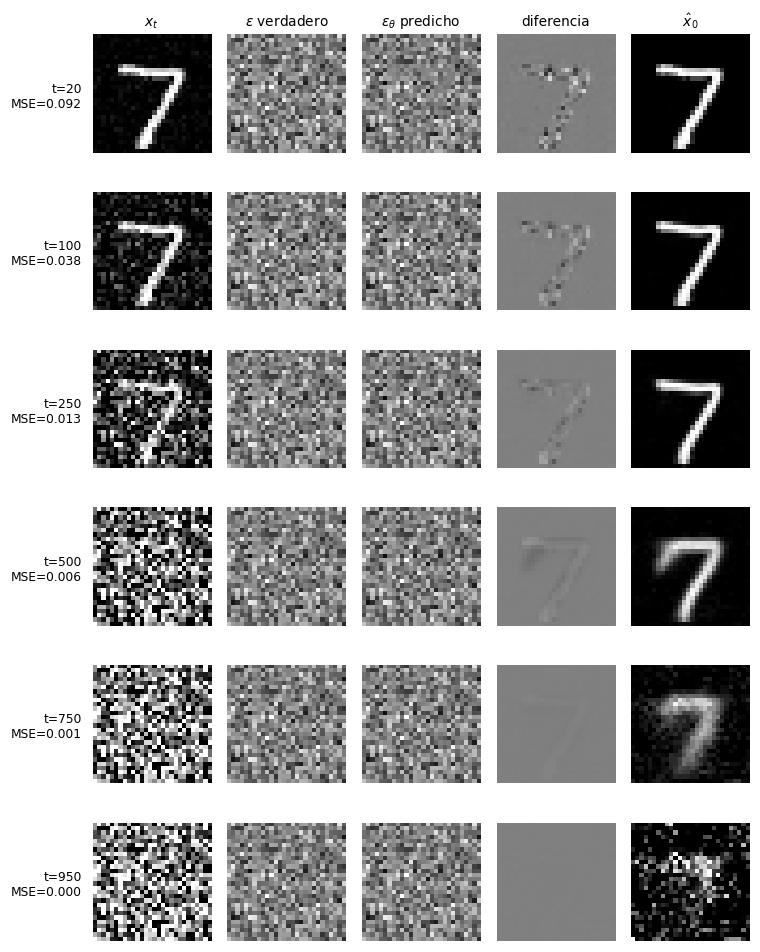

In [12]:
if unet_m is not None:
    Xt = td.leer_idx("t10k-images-idx3-ubyte").astype(np.float32) / 127.5 - 1
    Yt = td.leer_idx("t10k-labels-idx1-ubyte").astype(np.int64)
    x0_d = torch.tensor(Xt[:1][:, None], device=DEVICE)
    y0 = torch.tensor(Yt[:1], device=DEVICE)
    eps = torch.randn(x0_d.shape, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(SEED))
    ts = [20, 100, 250, 500, 750, 950]
    cols = ["$x_t$", "$\\epsilon$ verdadero", "$\\epsilon_\\theta$ predicho", "diferencia", "$\\hat x_0$"]
    fig, axs = plt.subplots(len(ts), 5, figsize=(7, 9))
    with torch.no_grad():
        for r, tt in enumerate(ts):
            ti = torch.full((1,), tt - 1, device=DEVICE, dtype=torch.long)
            xt = dif.q_sample(x0_d, ti, eps)
            ep = unet_m(xt, ti, y0)
            ab = dif.ab[tt - 1]
            x0h = (xt - (1 - ab).sqrt() * ep) / ab.sqrt()
            mse = F.mse_loss(ep, eps).item()
            for k, im in enumerate([xt, eps / 3, ep / 3, (ep - eps) / 3, x0h]):
                axs[r, k].imshow(im[0, 0].clamp(-1, 1).cpu(), cmap="gray", vmin=-1, vmax=1); axs[r, k].axis("off")
                if r == 0: axs[r, k].set_title(cols[k], fontsize=9)
            axs[r, 0].text(-3, 14, f"t={tt}\nMSE={mse:.3f}", ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

## Ejercicios

1. Repite la sección 3 con el horario coseno. ¿En qué paso $t$ la nube deja de reconocerse con cada horario?
2. Entrena el MLP 2D con $T=200$ en vez de $1000$ (reescala $\beta_t$ para que $\bar\alpha_T$ siga siendo pequeño). ¿Empeoran las muestras?
3. Cambia la red para que prediga $\mathbf x_0$ en lugar de $\boldsymbol\epsilon$ y adapta el paso inverso con la media del posterior. Compara la calidad.
4. En el muestreo, sustituye $\sigma_t^2=\tilde\beta_t$ por $\sigma_t^2=\beta_t$. ¿Se nota la diferencia en 2D?
5. Prueba escalas de guía $w\in\{0, 0.5, 1, 2, 5, 8\}$ con los paisajes. ¿A partir de qué $w$ los colores se saturan?
6. Con la red 2D, implementa dinámica de Langevin a $t$ fijo: $\mathbf x\leftarrow\mathbf x+\tfrac{\eta}{2}\,s_\theta(\mathbf x)+\sqrt{\eta}\,\mathbf z$. ¿Qué pasa si solo usas el $t$ más pequeño?